# Step 1: Data Cleaning

**Aim:** take `raw_energy_data.csv` (messy data) and make `cleaned_energy_data.csv` (correct data).

**Why do we clean data?** If the data has duplicates, empty cells or wrong numbers, every chart, SQL query and dashboard we make later will give wrong answers.

**What one row means:** one power plant, in one 4-hour block of one day. The `Hour` column is the start of the block (0, 4, 8, 12, 16, 20).

**Steps in this notebook**
1. Load the data and look at it
2. Find missing values
3. Remove duplicate rows
4. Fix text (spelling / capital letters)
5. Fix dates
6. Find wrong values
7. Fix missing and wrong values
8. Check the result and save

## Load the tools and the data
`pandas` is used for tables and `matplotlib` is used for charts.

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Folder where all the project files are kept
FOLDER = r"D:\RENEWABLE ENERGY PERFORMANCE Project"
if not os.path.exists(FOLDER):
    FOLDER = os.path.dirname(os.getcwd())      # if that folder is not found, use the folder above this notebook

DATA_FOLDER = os.path.join(FOLDER, "data")     # the CSV files are in the "data" folder
if not os.path.exists(DATA_FOLDER):
    DATA_FOLDER = FOLDER                        # if there is no "data" folder, they are in the main folder

raw_file = os.path.join(DATA_FOLDER, "raw_energy_data.csv")
clean_file = os.path.join(DATA_FOLDER, "cleaned_energy_data.csv")

fixed = {}     # we will write down here how many problems we fixed

In [3]:
df = pd.read_csv(raw_file)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Rows: 52740
Columns: 23


,Record_ID,Plant_ID,Plant_Name,Energy_Type,Region,City,Date,Hour,Energy_Generated_MWh,Installed_Capacity_MW,...,Solar_Irradiance,Rainfall_mm,Downtime_Hours,Maintenance_Hours,Plant_Status,Operating_Cost,Maintenance_Cost,Revenue,Efficiency_Percent,Availability_Percent
0,R000001,P001,Sunridge Solar Park,Solar,West,Jodhpur,2025-01-01,0,0.0,250,...,0.0,0.0,0.0,0.0,Operational,126573.51,0.0,0.0,92.15,100.0
1,R000002,P002,Helios Solar Farm,Solar,South,Tumakuru,2025-01-01,0,0.0,200,...,0.0,0.0,0.0,0.0,Operational,111413.29,0.0,0.0,90.27,100.0
2,R000003,P003,Aditya Solar Park,Solar,Central,Rewa,2025-01-01,0,0.0,150,...,0.0,0.0,0.0,0.0,Operational,85235.46,0.0,0.0,89.41,100.0
3,R000004,P004,Suryakiran Solar Plant,Solar,South,Ramanathapuram,2025-01-01,0,0.0,180,...,0.0,0.0,0.0,0.0,Operational,96426.46,0.0,0.0,88.73,100.0
4,R000005,P005,Dhoop Solar Park,Solar,West,Patan,2025-01-01,0,0.0,120,...,0.0,0.0,0.0,0.0,Operational,71263.11,0.0,0.0,84.75,100.0


**Look at the column types.** `Date` is shown as text (object), so we must convert it later. Many columns have fewer values than the total rows, so they have missing values.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 52740 entries, 0 to 52739
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Record_ID              52740 non-null  str    
 1   Plant_ID               52740 non-null  str    
 2   Plant_Name             52740 non-null  str    
 3   Energy_Type            52740 non-null  str    
 4   Region                 52740 non-null  str    
 5   City                   52740 non-null  str    
 6   Date                   52740 non-null  str    
 7   Hour                   52740 non-null  int64  
 8   Energy_Generated_MWh   52529 non-null  float64
 9   Installed_Capacity_MW  52740 non-null  int64  
 10  Capacity_Utilization   52583 non-null  float64
 11  Temperature_C          51951 non-null  float64
 12  Wind_Speed_kmh         52105 non-null  float64
 13  Solar_Irradiance       52214 non-null  float64
 14  Rainfall_mm            52109 non-null  float64
 15  Downtime_Hour

In [5]:
df.describe()

,Hour,Energy_Generated_MWh,Installed_Capacity_MW,Capacity_Utilization,Temperature_C,Wind_Speed_kmh,Solar_Irradiance,Rainfall_mm,Downtime_Hours,Maintenance_Hours,Operating_Cost,Maintenance_Cost,Revenue,Efficiency_Percent,Availability_Percent
count,52740.000000,52529.000000,52740.000000,52583.000000,51951.000000,52105.000000,52214.000000,52109.000000,52740.000000,52740.000000,52317.000000,52318.000000,5.242400e+04,52477.000000,52583.000000
mean,10.001289,187.184060,151.256921,28.663731,24.838796,17.577451,230.587247,1.036508,0.198436,0.222753,101127.003420,3510.315749,6.624109e+05,85.783162,95.060666
std,6.830610,236.168715,60.637471,28.310249,6.550584,15.215684,274.532398,4.528806,0.699653,0.739920,52008.362497,12761.827129,7.846930e+05,5.022944,17.373457
min,0.000000,-1118.607000,60.000000,0.000000,0.500000,0.300000,0.000000,0.000000,-1.000000,0.000000,34945.240000,0.000000,0.000000e+00,62.860000,0.000000
25%,4.000000,14.151000,100.000000,3.265000,21.000000,7.700000,0.000000,0.000000,0.000000,0.000000,67352.840000,0.000000,4.701910e+04,82.690000,100.000000
50%,12.000000,110.400000,150.000000,22.210000,25.400000,12.500000,97.000000,0.000000,0.000000,0.000000,86511.690000,0.000000,4.169844e+05,86.180000,100.000000
75%,16.000000,277.649000,180.000000,48.295000,29.400000,22.100000,542.600000,0.000000,0.000000,0.000000,118635.900000,0.000000,9.979205e+05,89.310000,100.000000
max,20.000000,11200.410000,300.000000,101.580000,41.000000,174.000000,861.200000,102.100000,6.000000,4.000000,312014.670000,224933.220000,4.061481e+06,129.670000,100.000000


## 1. Missing values
Count the empty cells in every column.

Energy_Generated_MWh    211
Capacity_Utilization    157
Temperature_C           789
Wind_Speed_kmh          635
Solar_Irradiance        526
Rainfall_mm             631
Operating_Cost          423
Maintenance_Cost        422
Revenue                 316
Efficiency_Percent      263
Availability_Percent    157
dtype: int64


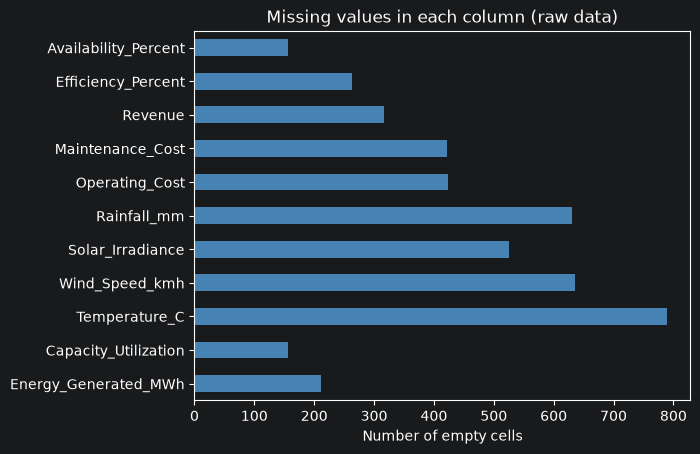

In [6]:
missing = df.isnull().sum()
missing = missing[missing > 0]
print(missing)

missing.plot(kind="barh", color="steelblue", title="Missing values in each column (raw data)")
plt.xlabel("Number of empty cells")
plt.show()

## 2. Duplicate rows
A duplicate row counts the same energy and revenue two times, so we remove it.

In [7]:
print("Duplicate rows:", df.duplicated().sum())

fixed["Duplicate rows removed"] = int(df.duplicated().sum())
df = df.drop_duplicates()
df = df.reset_index(drop=True)

print("Rows after removing duplicates:", len(df))

Duplicate rows: 180
Rows after removing duplicates: 52560


## 3. Fix text columns
The same word is written in different ways, for example `solar`, `SOLAR` and ` Solar `. Python treats them as different values, so we make them the same.

In [8]:
print("Before:", df["Energy_Type"].unique())

df["Plant_ID"] = df["Plant_ID"].str.strip().str.upper()
for col in ["Plant_Name", "Energy_Type", "Region", "City", "Plant_Status"]:
    df[col] = df[col].str.strip().str.title()      # remove extra spaces, make First Letter Capital

print("After :", df["Energy_Type"].unique())
print("Regions:", df["Region"].unique())
print("Status :", df["Plant_Status"].unique())

Before: <ArrowStringArray>
[ 'Solar',   'Wind',  'Hydro',   'wind',  'Wind ', ' Solar',  'hydro',
 'Solar ',   'WIND', 'Hydro ',  'SOLAR',  'HYDRO',  'solar',  ' Wind',
 ' Hydro']
Length: 15, dtype: str
After : <ArrowStringArray>
['Solar', 'Wind', 'Hydro']
Length: 3, dtype: str
Regions: <ArrowStringArray>
['West', 'South', 'Central', 'East', 'North']
Length: 5, dtype: str
Status : <ArrowStringArray>
['Operational', 'Partial Outage', 'Shutdown', 'Under Maintenance']
Length: 4, dtype: str


## 4. Fix the Date column
Most dates look like `2025-03-15`, but some look like `15/03/2025`. We try both formats and join the results.

In [9]:
date_format1 = pd.to_datetime(df["Date"], format="%Y-%m-%d", errors="coerce")
date_format2 = pd.to_datetime(df["Date"], format="%d/%m/%Y", errors="coerce")

fixed["Dates in the DD/MM/YYYY format"] = int(date_format1.isnull().sum())
df["Date"] = date_format1.fillna(date_format2)

print("Dates not converted:", df["Date"].isnull().sum())
print("First date:", df["Date"].min().date(), "  Last date:", df["Date"].max().date())

Dates not converted: 0
First date: 2025-01-01   Last date: 2025-12-31


## 5. Find wrong values
Some numbers are not possible in real life. Our rules:
- Energy cannot be negative.
- A plant cannot make more than `capacity x 4 hours` in one block.
- Energy and `Capacity_Utilization` must agree (`Energy = Capacity_Utilization / 100 x maximum energy`).
- Efficiency and availability must be between 0 and 100.
- Downtime must be between 0 and 4 hours (a block is only 4 hours long).

In [10]:
max_energy = df["Installed_Capacity_MW"] * 4       # most energy a plant can make in one 4-hour block

print("Negative energy          :", (df["Energy_Generated_MWh"] < 0).sum())
print("Energy above the maximum :", (df["Energy_Generated_MWh"] > max_energy).sum())

expected_energy = df["Capacity_Utilization"] / 100 * max_energy
print("Energy not matching utilization:", ((df["Energy_Generated_MWh"] - expected_energy).abs() > 1).sum())

print("Efficiency above 100     :", (df["Efficiency_Percent"] > 100).sum())
print("Downtime outside 0 to 4  :", ((df["Downtime_Hours"] < 0) | (df["Downtime_Hours"] > 4)).sum())
print("Availability outside 0-100:", ((df["Availability_Percent"] < 0) | (df["Availability_Percent"] > 100)).sum())

Negative energy          : 25
Energy above the maximum : 17
Energy not matching utilization: 42
Efficiency above 100     : 40
Downtime outside 0 to 4  : 20
Availability outside 0-100: 0


## 6. Fix missing and wrong values
Our idea: **first try to calculate the value from another column. If that is not possible, use the median of similar rows.** (The median is the middle value, so it is not changed by very big or very small numbers.)

### 6.1 Energy generated
Utilization is correct in our data, so a wrong energy value can be calculated again from it. If energy and utilization disagree, we trust utilization.

In [11]:
df["Month"] = df["Date"].dt.month

# Rows where energy is missing, not possible, or does not match utilization (more than 1 MWh apart)
expected_energy = df["Capacity_Utilization"] / 100 * max_energy
not_possible = ~df["Energy_Generated_MWh"].between(0, max_energy)
not_matching = (df["Energy_Generated_MWh"] - expected_energy).abs() > 1
wrong_energy = not_possible | not_matching

# Method 1: calculate energy from Capacity_Utilization (only if utilization is correct)
can_calculate = wrong_energy & df["Capacity_Utilization"].between(0, 100)
df.loc[can_calculate, "Energy_Generated_MWh"] = expected_energy.round(3)

# Method 2: for the rest, use the median of the same plant, month and hour block
wrong_energy_now = ~df["Energy_Generated_MWh"].between(0, max_energy)
df.loc[wrong_energy_now, "Energy_Generated_MWh"] = None
median_energy = df.groupby(["Plant_ID", "Month", "Hour"])["Energy_Generated_MWh"].transform("median")
df["Energy_Generated_MWh"] = df["Energy_Generated_MWh"].fillna(median_energy).round(3)

# Calculate utilization again for all rows so both columns always agree
df["Capacity_Utilization"] = (df["Energy_Generated_MWh"] / max_energy * 100).round(2)

fixed["Energy values fixed"] = int(wrong_energy.sum())
print("Energy values fixed:", wrong_energy.sum())

Energy values fixed: 259


### 6.2 Downtime and availability
`Availability = (4 - Downtime) / 4 x 100`. If downtime is wrong we calculate it from availability. If we cannot, we use 0 (no proof of any breakdown). Then availability is calculated again for every row.

In [12]:
wrong_downtime = ~df["Downtime_Hours"].between(0, 4)
fixed["Downtime values fixed"] = int(wrong_downtime.sum())
fixed["Availability values missing"] = int(df["Availability_Percent"].isnull().sum())

# Method 1: calculate downtime from availability
can_calculate = wrong_downtime & df["Availability_Percent"].between(0, 100)
df.loc[can_calculate, "Downtime_Hours"] = ((100 - df["Availability_Percent"]) / 100 * 4).round(2)

# Method 2: if still wrong, use 0
df.loc[~df["Downtime_Hours"].between(0, 4), "Downtime_Hours"] = 0

# Availability again for all rows
df["Availability_Percent"] = ((4 - df["Downtime_Hours"]) / 4 * 100).round(2)
print("Downtime values fixed:", wrong_downtime.sum())

Downtime values fixed: 20


### 6.3 Efficiency
Efficiency above 100% is not possible. We remove those values and fill them (and the missing ones) with the median of the same plant and same status.

In [13]:
wrong_efficiency = ~df["Efficiency_Percent"].between(0, 100)
fixed["Efficiency values fixed"] = int(wrong_efficiency.sum())

df.loc[wrong_efficiency, "Efficiency_Percent"] = None
median_eff = df.groupby(["Plant_ID", "Plant_Status"])["Efficiency_Percent"].transform("median")
df["Efficiency_Percent"] = df["Efficiency_Percent"].fillna(median_eff).round(2)
print("Efficiency values fixed:", wrong_efficiency.sum())

Efficiency values fixed: 302


### 6.4 Weather columns
Weather changes with the month and with the time of day (night is cold, afternoon is hot). So we fill a missing value with the median of the same plant, same month and same hour block.

In [14]:
weather_columns = ["Temperature_C", "Wind_Speed_kmh", "Solar_Irradiance", "Rainfall_mm"]

for col in weather_columns:
    fixed["Missing " + col] = int(df[col].isnull().sum())
    median_value = df.groupby(["Plant_ID", "Month", "Hour"])[col].transform("median")
    df[col] = df[col].fillna(median_value).round(1)
    print(col, "- missing before:", fixed["Missing " + col], " after:", df[col].isnull().sum())

Temperature_C - missing before: 788  after: 0
Wind_Speed_kmh - missing before: 630  after: 0
Solar_Irradiance - missing before: 525  after: 0
Rainfall_mm - missing before: 630  after: 0


### 6.5 Costs and revenue
- **Operating cost:** it grows with the energy generated. For each plant we draw a straight line (cost against energy) and use it to fill the missing costs.
- **Maintenance cost:** if there were 0 maintenance hours, the cost is 0. Otherwise `cost = maintenance hours x cost of one hour`. The cost of one hour is the median of the same plant and status.
- **Revenue:** `Revenue = Energy x price per MWh`. The price is the median price of that plant.

In [15]:
import numpy as np

# Operating cost: a straight line for each plant  (cost = start + slope x energy)
fixed["Missing Operating_Cost"] = int(df["Operating_Cost"].isnull().sum())
for plant_id in df["Plant_ID"].unique():
    this_plant = df["Plant_ID"] == plant_id
    known = this_plant & df["Operating_Cost"].notnull()
    slope, start = np.polyfit(df.loc[known, "Energy_Generated_MWh"], df.loc[known, "Operating_Cost"], 1)
    gap = this_plant & df["Operating_Cost"].isnull()
    df.loc[gap, "Operating_Cost"] = start + slope * df.loc[gap, "Energy_Generated_MWh"]
df["Operating_Cost"] = df["Operating_Cost"].round(2)

# Maintenance cost: hours x cost of one hour
fixed["Missing Maintenance_Cost"] = int(df["Maintenance_Cost"].isnull().sum())
df.loc[df["Maintenance_Cost"].isnull() & (df["Maintenance_Hours"] == 0), "Maintenance_Cost"] = 0.0
cost_of_one_hour = df["Maintenance_Cost"] / df["Maintenance_Hours"].where(df["Maintenance_Hours"] > 0)
typical = cost_of_one_hour.groupby([df["Plant_ID"], df["Plant_Status"]]).transform("median")
typical = typical.fillna(cost_of_one_hour.groupby(df["Plant_ID"]).transform("median"))
gap = df["Maintenance_Cost"].isnull()
df.loc[gap, "Maintenance_Cost"] = (df["Maintenance_Hours"] * typical).round(2)

# Revenue: energy x price per MWh
fixed["Missing Revenue"] = int(df["Revenue"].isnull().sum())
price = (df["Revenue"] / df["Energy_Generated_MWh"]).where(df["Energy_Generated_MWh"] > 0)
price = price.groupby(df["Plant_ID"]).transform("median")
gap = df["Revenue"].isnull()
df.loc[gap, "Revenue"] = (df["Energy_Generated_MWh"] * price).round(2)

print("Missing values left in cost and revenue columns:",
      df[["Operating_Cost", "Maintenance_Cost", "Revenue"]].isnull().sum().sum())

Missing values left in cost and revenue columns: 0


## 7. Outlier check
After the fixes, we check if any strange values are left. A box plot shows the normal range as a box. Dots outside the whiskers are unusual values.

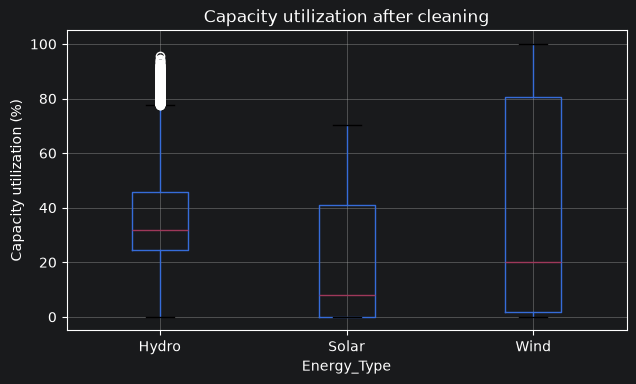

In [16]:
df.boxplot(column="Capacity_Utilization", by="Energy_Type", figsize=(7, 4))
plt.title("Capacity utilization after cleaning")
plt.suptitle("")
plt.ylabel("Capacity utilization (%)")
plt.show()

The values look normal. Wind and hydro have a big box because their output depends on the season and weather. These are real changes and not mistakes, so we keep them.

## 8. Final checks and save
Before saving, we check that the data follows all our rules. `assert` stops the code with an error if a rule is broken.

In [17]:
df = df.drop(columns=["Month"])
df = df.sort_values(["Date", "Hour", "Plant_ID"]).reset_index(drop=True)

assert df.isnull().sum().sum() == 0, "There are still missing values"
assert df.duplicated().sum() == 0, "There are still duplicate rows"
assert df["Record_ID"].is_unique, "Record_ID is not unique"
assert len(df) == 24 * 365 * 6, "Row count is not 24 plants x 365 days x 6 blocks"
assert df["Energy_Generated_MWh"].min() >= 0, "Negative energy found"
assert df["Efficiency_Percent"].between(0, 100).all(), "Efficiency outside 0-100"
assert df["Downtime_Hours"].between(0, 4).all(), "Downtime outside 0-4"
assert df["Availability_Percent"].between(0, 100).all(), "Availability outside 0-100"
assert df["Capacity_Utilization"].between(0, 100).all(), "Utilization outside 0-100"
assert set(df["Energy_Type"]) == {"Solar", "Wind", "Hydro"}, "Unexpected energy type"
print("All checks passed.")

df.to_csv(clean_file, index=False, date_format="%Y-%m-%d")
print("Saved", len(df), "rows to cleaned_energy_data.csv")

All checks passed.
Saved 52560 rows to cleaned_energy_data.csv


## 9. Summary of the cleaning

In [18]:
summary = pd.Series(fixed, name="Number of problems")
print(summary.to_string())
print()
print("Raw rows     :", 52740)
print("Cleaned rows :", len(df))

Duplicate rows removed             180
Dates in the DD/MM/YYYY format    1576
Energy values fixed                259
Downtime values fixed               20
Availability values missing        157
Efficiency values fixed            302
Missing Temperature_C              788
Missing Wind_Speed_kmh             630
Missing Solar_Irradiance           525
Missing Rainfall_mm                630
Missing Operating_Cost             420
Missing Maintenance_Cost           420
Missing Revenue                    315

Raw rows     : 52740
Cleaned rows : 52560


### Key numbers (we will check these again in MySQL, Power BI and Streamlit)

In [19]:
print("Records                   :", len(df))
print("Total energy (MWh)        :", round(df["Energy_Generated_MWh"].sum(), 3))
print("Total revenue (INR)       :", round(df["Revenue"].sum(), 2))
print("Total operating cost (INR):", round(df["Operating_Cost"].sum(), 2))
print("Total maintenance cost    :", round(df["Maintenance_Cost"].sum(), 2))
print("Average efficiency (%)    :", round(df["Efficiency_Percent"].mean(), 2))
print("Average of Capacity_Utilization column (%):", round(df["Capacity_Utilization"].mean(), 2))

Records                   : 52560
Total energy (MWh)        : 9805015.292
Total revenue (INR)       : 34813097321.41
Total operating cost (INR): 5315314058.31
Total maintenance cost    : 184486058.66
Average efficiency (%)    : 85.76
Average of Capacity_Utilization column (%): 28.68
